In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datashader as ds
import time

C:\Users\alexi\Desktop\LIDI\Actividad_2\.venv\Lib\site-packages\dask\dataframe\__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


In [2]:
# Cargar datos desde la carpeta data
df = pd.read_parquet("../data/dataset_5M.parquet")
print("Dimensiones del dataset:", df.shape)

# Comprobar rangos de las variables continuas
print("Edad min/max:", df["edad"].min(), df["edad"].max())
print("Altura min/max:", df["altura"].min(), df["altura"].max())

Dimensiones del dataset: (5000000, 5)
Edad min/max: -19.761751173733877 100.40566326613538
Altura min/max: 118.81033159067783 220.76479786355287


In [3]:
# 1. Definir la cuadrícula (100x100 bins)
canvas = ds.Canvas(
    plot_width=100,
    plot_height=100,
    x_range=(df["edad"].min(), df["edad"].max()),
    y_range=(df["altura"].min(), df["altura"].max())
)

# 2. Medir tiempo de agregación por puntos
inicio = time.perf_counter()
agg = canvas.points(df, "edad", "altura", agg=ds.count())
fin = time.perf_counter()

tiempo_datashader = fin - inicio
print(f"Tiempo de agregación Datashader: {tiempo_datashader:.4f} segundos")

Tiempo de agregación Datashader: 0.8870 segundos


In [4]:
print(agg)

<xarray.DataArray (altura: 100, edad: 100)> Size: 40kB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(100, 100), dtype=uint32)
Coordinates:
  * altura   (altura) float64 800B 119.3 120.3 121.4 122.4 ... 218.2 219.2 220.3
  * edad     (edad) float64 800B -19.16 -17.96 -16.76 -15.56 ... 97.4 98.6 99.8
Attributes:
    x_range:  (np.float64(-19.761751173733877), np.float64(100.40566326613538))
    y_range:  (np.float64(118.81033159067783), np.float64(220.76479786355287))


In [5]:
datos_originales = len(df)
celdas_totales = agg.size
celdas_ocupadas = int((agg.values > 0).sum())

reduccion_representacion = (1 - celdas_ocupadas / datos_originales) * 100

print(f"Datos originales: {datos_originales:,}")
print(f"Celdas totales: {celdas_totales:,}")
print(f"Celdas ocupadas: {celdas_ocupadas:,}")
print(f"Reducción de representación: {reduccion_representacion:.4f}%")

Datos originales: 5,000,000
Celdas totales: 10,000
Celdas ocupadas: 5,876
Reducción de representación: 99.8825%


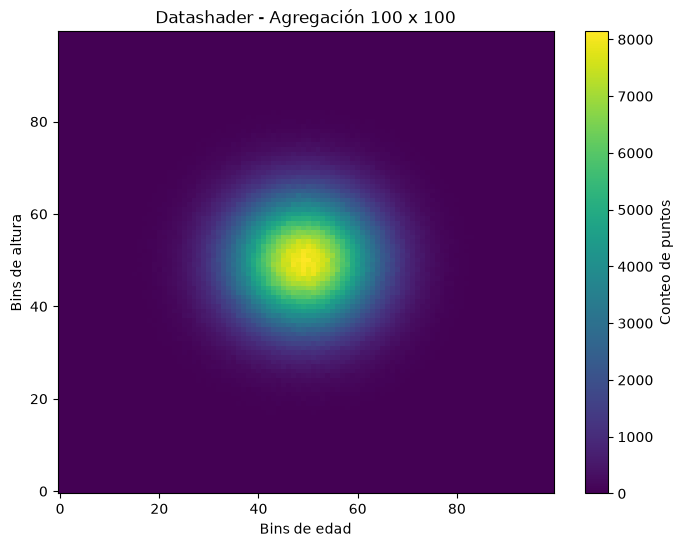

In [6]:
plt.figure(figsize=(8, 6))
plt.imshow(agg.values, origin="lower", aspect="auto", cmap="viridis")
plt.title("Datashader - Agregación 100 x 100")
plt.xlabel("Bins de edad")
plt.ylabel("Bins de altura")
plt.colorbar(label="Conteo de puntos")

# Guardar la imagen antes de mostrarla
plt.savefig("../resultados/graficos/datashader_100x100.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
resoluciones = [25, 50, 100, 200]
resultados_datashader = []

for res in resoluciones:
    c = ds.Canvas(
        plot_width=res,
        plot_height=res,
        x_range=(df["edad"].min(), df["edad"].max()),
        y_range=(df["altura"].min(), df["altura"].max())
    )
    
    t0 = time.perf_counter()
    a = c.points(df, "edad", "altura", agg=ds.count())
    t1 = time.perf_counter()
    
    ocupadas = int((a.values > 0).sum())
    
    resultados_datashader.append({
        "resolucion": f"{res}x{res}",
        "celdas_totales": a.size,
        "celdas_ocupadas": ocupadas,
        "tiempo_segundos": t1 - t0,
        "reduccion_pct": (1 - ocupadas / len(df)) * 100
    })

# Convertir a DataFrame y guardar
tabla_datashader = pd.DataFrame(resultados_datashader)
tabla_datashader.to_csv("../resultados/tablas/datashader.csv", index=False)

print("Resultados de Datashader guardados en ../resultados/tablas/datashader.csv")
tabla_datashader

Resultados de Datashader guardados en ../resultados/tablas/datashader.csv


,resolucion,celdas_totales,celdas_ocupadas,tiempo_segundos,reduccion_pct
0,25x25,625,467,0.037089,99.99066
1,50x50,2500,1682,0.033526,99.96636
2,100x100,10000,5876,0.032928,99.88248
3,200x200,40000,20145,0.034129,99.59710
